**Aim**

To write SQL queries to extract meaningful insights from data and create visualizations using a Business Intelligence (BI) tool such as Tableau or Power BI.

**Theory**

SQL (Structured Query Language) is used to retrieve, filter, group, and analyze data stored in databases. SQL commands such as SELECT, WHERE, GROUP BY, ORDER BY, and aggregate functions like SUM() help extract useful information from datasets.

Business Intelligence (BI) tools such as Tableau and Microsoft Power BI convert data into visual representations like bar charts, pie charts, and dashboards. These visualizations help users identify trends, compare values, understand patterns, and make better business decisions.

In this experiment, SQL queries are used to analyze sales data, such as total sales by product, sales by region, and product quantities sold. The query results are then visualized to present the insights clearly.

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

# Create a database
conn = sqlite3.connect("sales.db")

# Create sample sales data
data = {
    "product": ["Laptop", "Mobile", "Tablet", "Laptop",
                "Mobile", "Tablet", "Laptop", "Mobile"],
    "category": ["Electronics", "Electronics", "Electronics",
                 "Electronics", "Electronics", "Electronics",
                 "Electronics", "Electronics"],
    "quantity": [5, 10, 8, 3, 12, 6, 4, 7],
    "price": [50000, 20000, 15000, 50000,
              20000, 15000, 50000, 20000],
    "region": ["West", "East", "North", "West",
               "South", "North", "East", "South"]
}

df = pd.DataFrame(data)

# Store the data in SQL table
df.to_sql("sales", conn, if_exists="replace", index=False)

print("Sales table created successfully!")
display(df)

Sales table created successfully!


,product,category,quantity,price,region
0,Laptop,Electronics,5,50000,West
1,Mobile,Electronics,10,20000,East
2,Tablet,Electronics,8,15000,North
3,Laptop,Electronics,3,50000,West
4,Mobile,Electronics,12,20000,South
5,Tablet,Electronics,6,15000,North
6,Laptop,Electronics,4,50000,East
7,Mobile,Electronics,7,20000,South


In [ ]:

query = "SELECT * FROM sales"

result = pd.read_sql_query(query, conn)
display(result)

,product,category,quantity,price,region
0,Laptop,Electronics,5,50000,West
1,Mobile,Electronics,10,20000,East
2,Tablet,Electronics,8,15000,North
3,Laptop,Electronics,3,50000,West
4,Mobile,Electronics,12,20000,South
5,Tablet,Electronics,6,15000,North
6,Laptop,Electronics,4,50000,East
7,Mobile,Electronics,7,20000,South


In [ ]:

query = """
SELECT product,
       SUM(quantity * price) AS total_sales
FROM sales
GROUP BY product
ORDER BY total_sales DESC;
"""

product_sales = pd.read_sql_query(query, conn)
display(product_sales)

,product,total_sales
0,Laptop,600000
1,Mobile,580000
2,Tablet,210000


In [ ]:

query = """
SELECT region,
       SUM(quantity * price) AS total_sales
FROM sales
GROUP BY region
ORDER BY total_sales DESC;
"""

region_sales = pd.read_sql_query(query, conn)
display(region_sales)

,region,total_sales
0,West,400000
1,East,400000
2,South,380000
3,North,210000


In [ ]:

query = """
SELECT product,
       SUM(quantity) AS total_quantity
FROM sales
GROUP BY product
ORDER BY total_quantity DESC;
"""

best_selling = pd.read_sql_query(query, conn)
display(best_selling)

,product,total_quantity
0,Mobile,29
1,Tablet,14
2,Laptop,12


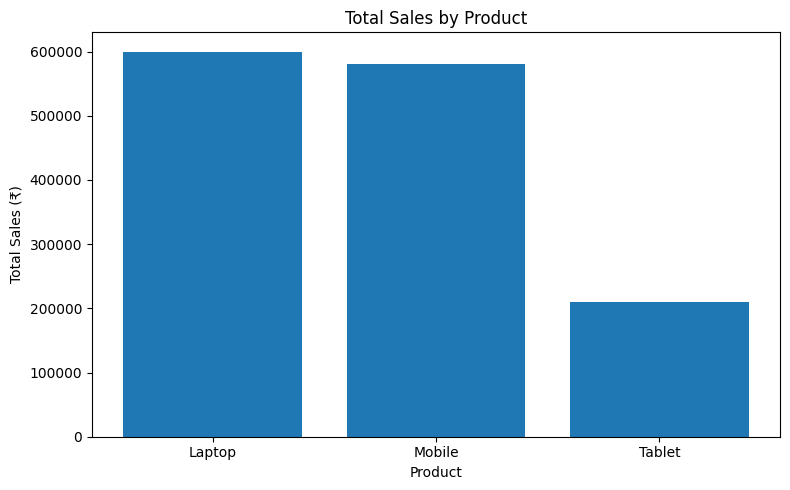

In [ ]:

plt.figure(figsize=(8, 5))

plt.bar(product_sales["product"],
        product_sales["total_sales"])

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales (₹)")
plt.tight_layout()
plt.show()

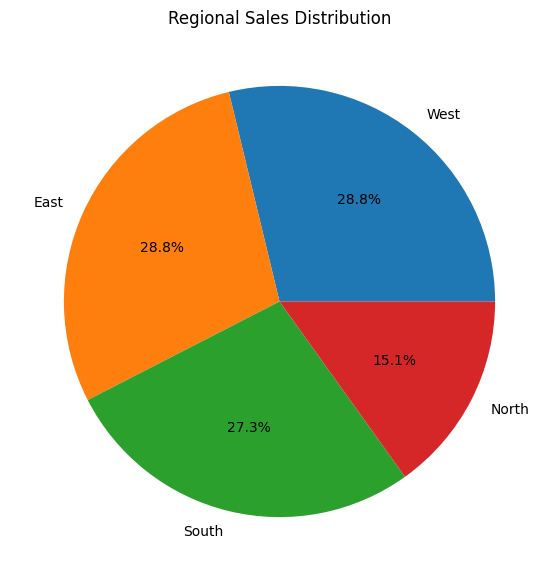

In [ ]:

plt.figure(figsize=(7, 7))

plt.pie(
    region_sales["total_sales"],
    labels=region_sales["region"],
    autopct="%1.1f%%"
)

plt.title("Regional Sales Distribution")
plt.show()

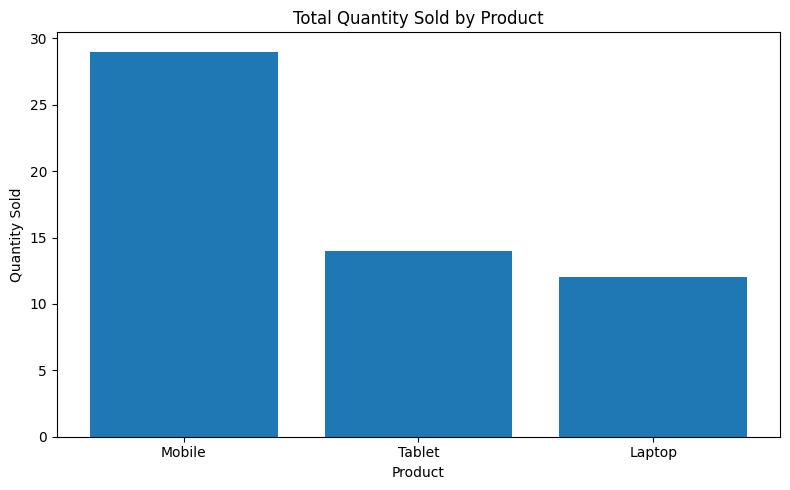

In [ ]:

plt.figure(figsize=(8, 5))

plt.bar(best_selling["product"],
        best_selling["total_quantity"])

plt.title("Total Quantity Sold by Product")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.tight_layout()
plt.show()

In [ ]:

top_product = product_sales.iloc[0]
top_region = region_sales.iloc[0]
top_quantity = best_selling.iloc[0]

print("BUSINESS INSIGHTS")
print("-----------------")
print("Highest revenue product:", top_product["product"])
print("Highest revenue:", top_product["total_sales"])
print("Top sales region:", top_region["region"])
print("Best-selling product by quantity:",
      top_quantity["product"])

BUSINESS INSIGHTS
-----------------
Highest revenue product: Laptop
Highest revenue: 600000
Top sales region: West
Best-selling product by quantity: Mobile


In [ ]:

conn.close()
print("Database connection closed successfully!")

Database connection closed successfully!


**Conclusion**

SQL queries were used to extract meaningful insights from sales data, and visualizations were created to compare product sales, regional sales, and quantities sold. This experiment demonstrated how SQL and data visualization help transform raw data into useful information for business decision-making.